In [420]:
import pandas as pd
df=pd.read_excel("/content/Student performance balanced missior.xlsm")


In [421]:
df.head()

,Gender,Parental Education Level,Lunch Type,Test Preparation Course,Study Time,Absences,Math Score,Reading Score,Writing Score
0,Male,Bachelor,Standard,NaN,12.7,6,74.2,68.7,67.7
1,Female,College,Standard,NaN,8.1,1,78.0,72.5,62.4
2,Male,College,Standard,NaN,10.8,5,67.0,72.0,72.9
3,Male,Bachelor,Standard,NaN,12.5,3,71.2,76.8,79.8
4,Male,Bachelor,Standard,Completed,9.9,4,82.9,75.9,75.7


In [422]:
data_columns=df.columns
data_columns

Index(['Gender', 'Parental Education Level', 'Lunch Type',
       'Test Preparation Course', 'Study Time', 'Absences', 'Math Score',
       'Reading Score', 'Writing Score'],
      dtype='object')

In [423]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Gender                    1000 non-null   object 
 1   Parental Education Level  1000 non-null   object 
 2   Lunch Type                1000 non-null   object 
 3   Test Preparation Course   486 non-null    object 
 4   Study Time                1000 non-null   float64
 5   Absences                  1000 non-null   int64  
 6   Math Score                1000 non-null   float64
 7   Reading Score             1000 non-null   float64
 8   Writing Score             1000 non-null   float64
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


In [424]:
df.describe()

,Study Time,Absences,Math Score,Reading Score,Writing Score
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,9.97700,4.921000,71.310100,68.393100,66.653400
std,3.08813,2.086891,10.269462,9.660793,10.218016
min,1.00000,0.000000,42.800000,36.100000,30.800000
25%,7.90000,3.000000,64.100000,61.900000,60.000000
50%,9.90000,5.000000,71.600000,68.500000,66.650000
75%,12.02500,6.000000,78.425000,74.925000,73.800000
max,20.00000,14.000000,100.000000,100.000000,100.000000


In [425]:
df.isnull().sum()

,0
Gender,0
Parental Education Level,0
Lunch Type,0
Test Preparation Course,514
Study Time,0
Absences,0
Math Score,0
Reading Score,0
Writing Score,0


In [426]:
df.duplicated().sum()

np.int64(0)

In [427]:
df['Test Preparation Course'].value_counts()

,count
Test Preparation Course,
Completed,486


In [428]:
df['Test Preparation Course'] = df['Test Preparation Course'].fillna("Not completed")

In [429]:
df.isna().sum()

,0
Gender,0
Parental Education Level,0
Lunch Type,0
Test Preparation Course,0
Study Time,0
Absences,0
Math Score,0
Reading Score,0
Writing Score,0


In [430]:
for c_col in df.select_dtypes(include='object'):
    print(c_col)
    print(df[c_col].unique())
    print()

Gender
['Male' 'Female']

Parental Education Level
['Bachelor' 'College' 'High School' 'Master']

Lunch Type
['Standard' 'Free/Reduced']

Test Preparation Course
['Not completed' 'Completed']



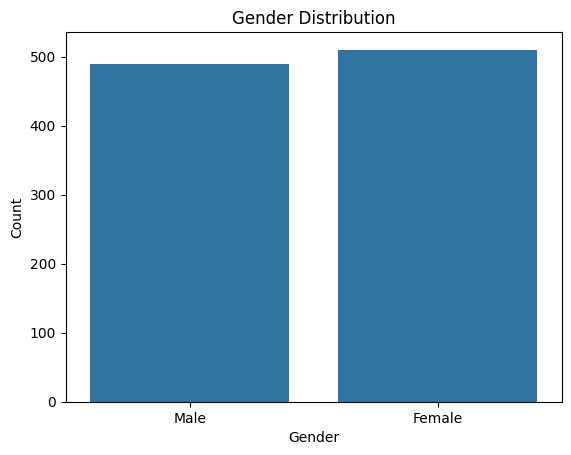

In [431]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Gender',data=df)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution')
plt.show()


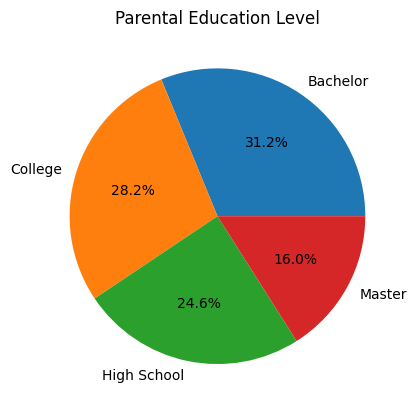

In [432]:
plt.pie(df['Parental Education Level'].value_counts(), labels=df['Parental Education Level'].unique(), autopct='%1.1f%%')
plt.title('Parental Education Level')
plt.show()

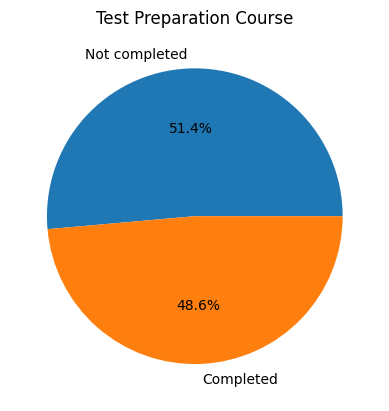

In [433]:
plt.pie(df['Test Preparation Course'].value_counts(), labels=df['Test Preparation Course'].unique(), autopct='%1.1f%%')
plt.title('Test Preparation Course')
plt.show()

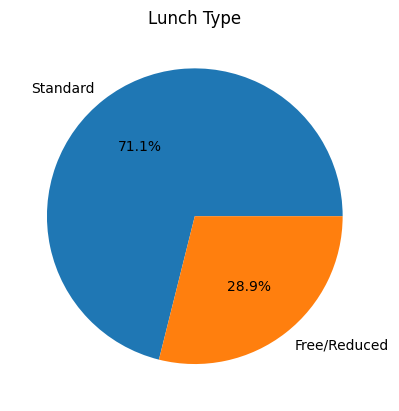

In [434]:
plt.pie(df['Lunch Type'].value_counts(), labels=df['Lunch Type'].unique(), autopct='%1.1f%%')
plt.title('Lunch Type')
plt.show()

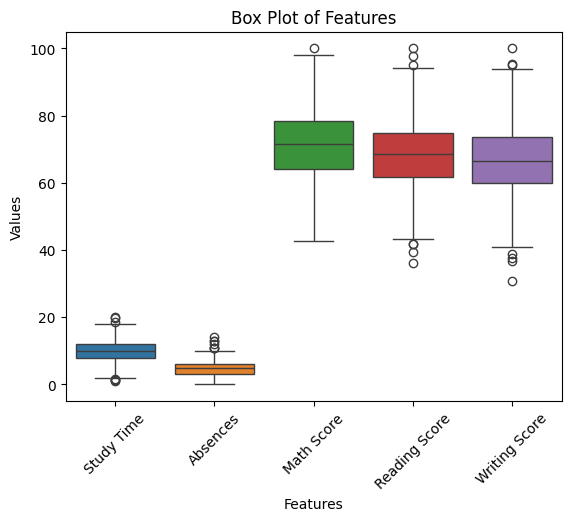

In [435]:
sns.boxplot(data=df)
plt.xlabel('Features')
plt.ylabel('Values')
plt.title('Box Plot of Features')
plt.xticks(rotation=45)
plt.show()

In [436]:
for n_col in df.select_dtypes(include='number').columns:
    print(n_col)
    print(df[n_col].min())
    print(df[n_col].max())
    print()
    q1 = df[n_col].quantile(0.25)
    q3 = df[n_col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    df[n_col] = df[n_col].clip(lower_bound, upper_bound)

Study Time
1.0
20.0

Absences
0
14

Math Score
42.8
100.0

Reading Score
36.1
100.0

Writing Score
30.8
100.0



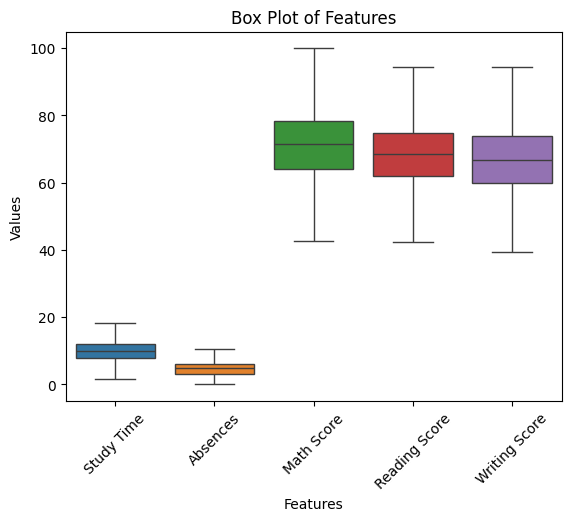

In [437]:
sns.boxplot(data=df)
plt.xlabel('Features')
plt.ylabel('Values')
plt.title('Box Plot of Features')
plt.xticks(rotation=45)
plt.show()

In [438]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Gender                    1000 non-null   object 
 1   Parental Education Level  1000 non-null   object 
 2   Lunch Type                1000 non-null   object 
 3   Test Preparation Course   1000 non-null   object 
 4   Study Time                1000 non-null   float64
 5   Absences                  1000 non-null   float64
 6   Math Score                1000 non-null   float64
 7   Reading Score             1000 non-null   float64
 8   Writing Score             1000 non-null   float64
dtypes: float64(5), object(4)
memory usage: 70.4+ KB


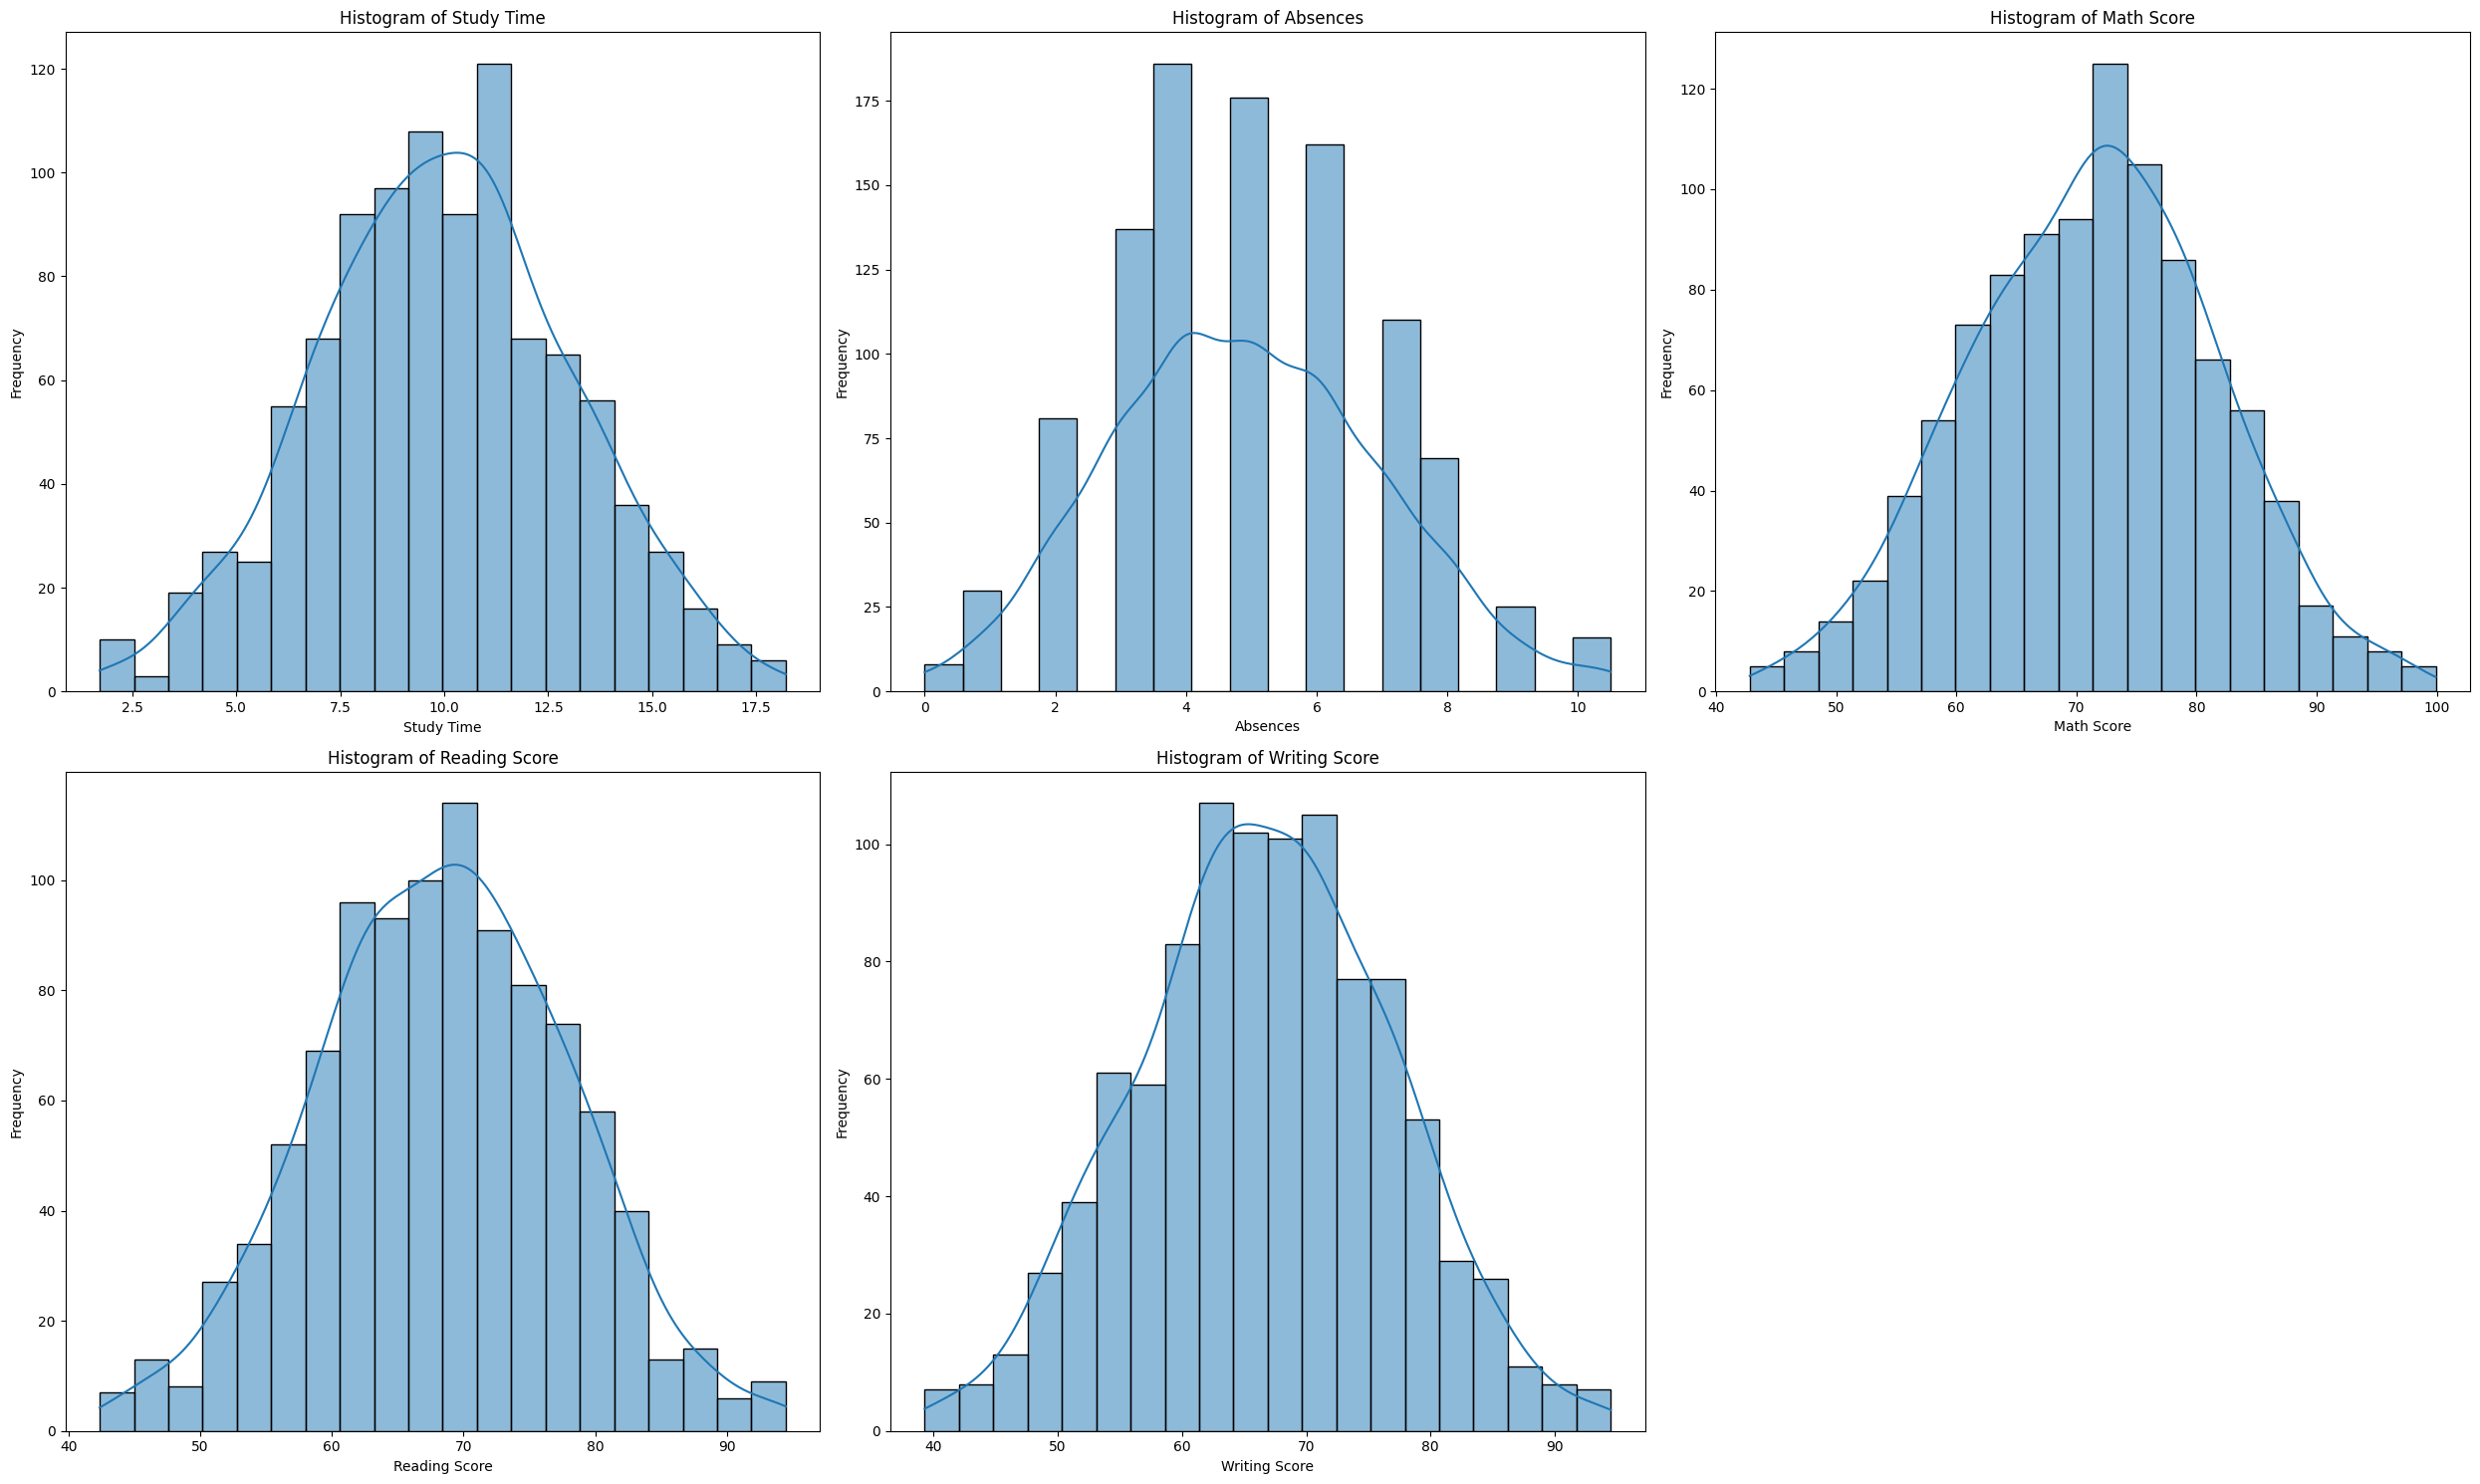

In [439]:
num_cols = df.select_dtypes(include='number').columns
plt.figure(figsize=(25, 15))
for i, n_col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df, x=n_col, kde=True)
    plt.xlabel(n_col)
    plt.ylabel('Frequency')
    plt.title('Histogram of ' + n_col)

plt.tight_layout()
plt.show()

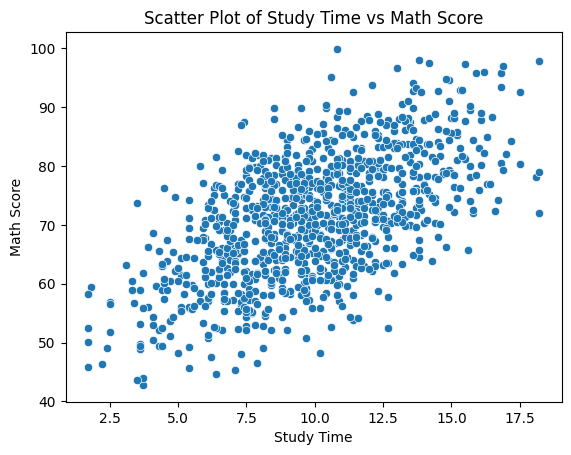

In [412]:
sns.scatterplot(data=df, x='Study Time', y='Math Score')
plt.xlabel('Study Time')
plt.ylabel('Math Score')
plt.title('Scatter Plot of Study Time vs Math Score')
plt.show()

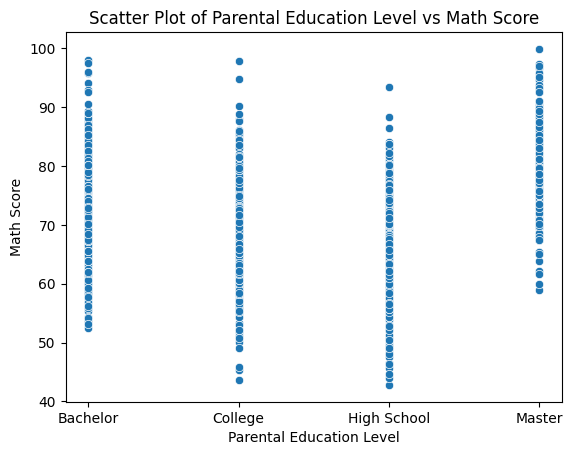

In [413]:
sns.scatterplot(data=df, x='Parental Education Level', y='Math Score')
plt.xlabel('Parental Education Level')
plt.ylabel('Math Score')
plt.title('Scatter Plot of Parental Education Level vs Math Score')
plt.show()

In [414]:
X=df.drop(['Math Score','Reading Score','Writing Score'],axis=1)
y=df[['Math Score','Reading Score','Writing Score']]
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(800, 6) (200, 6) (800, 3) (200, 3)


In [415]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

MMS = MinMaxScaler()
num_cols = X_train.select_dtypes(include='number').columns
X_train[num_cols] = MMS.fit_transform(X_train[num_cols])
X_test[num_cols] = MMS.transform(X_test[num_cols])


In [416]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for c_col in X_train.select_dtypes(include='object'):
    X_train[c_col]=le.fit_transform(X_train[c_col])
    X_test[c_col]=le.transform(X_test[c_col])


Linear Regression
MSE: 58.16
R2 Score: 0.41
________________________________________


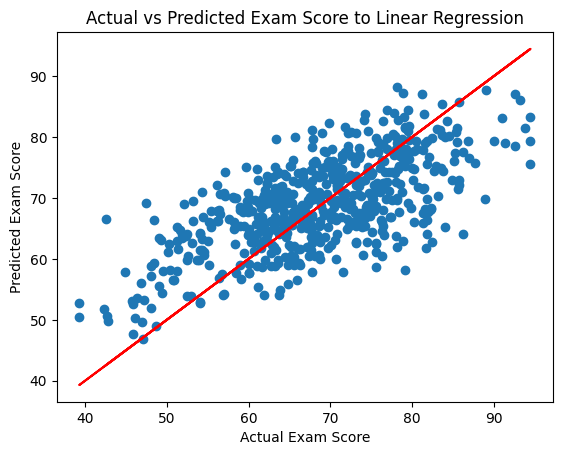

Decision Tree
MSE: 58.01
R2 Score: 0.41
________________________________________


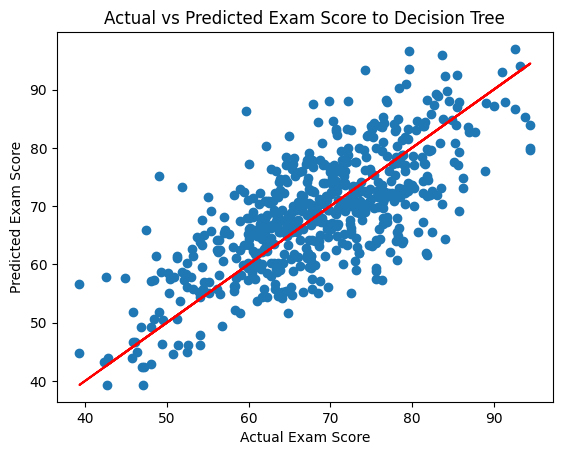

Random Forest
MSE: 32.68
R2 Score: 0.67
________________________________________


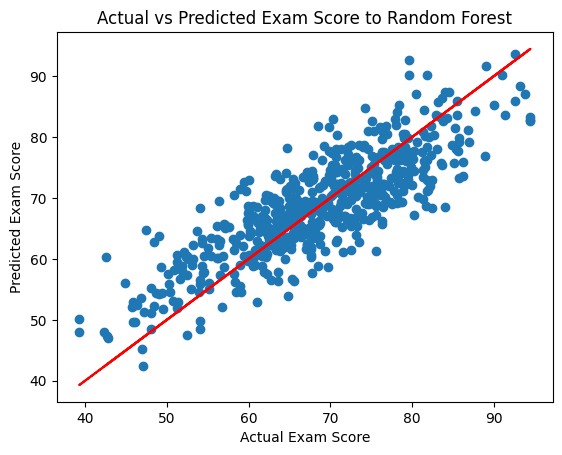

In [417]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

lr=LinearRegression()
dt=DecisionTreeRegressor()
rf=RandomForestRegressor()

models=[lr,dt,rf]
model_names=['Linear Regression','Decision Tree','Random Forest']

for model,name in zip(models,model_names):
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    mse=mean_squared_error(y_test,y_pred)
    r2=r2_score(y_test,y_pred)
    print(name)
    print('MSE:',np.round(mse,2))
    print('R2 Score:',np.round(r2,2))
    print("_"*40)
    plt.scatter(y_test,y_pred)
    plt.plot(y_test,y_test,color='red')
    plt.xlabel('Actual Exam Score')
    plt.ylabel('Predicted Exam Score')
    plt.title(f'Actual vs Predicted Exam Score to {name}')
    plt.show()

Rondom Forist
Best Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'max_depth': 10}
Best R2 Score: 0.6991112307101266
MSE: 31.07
R2 Score: 0.68


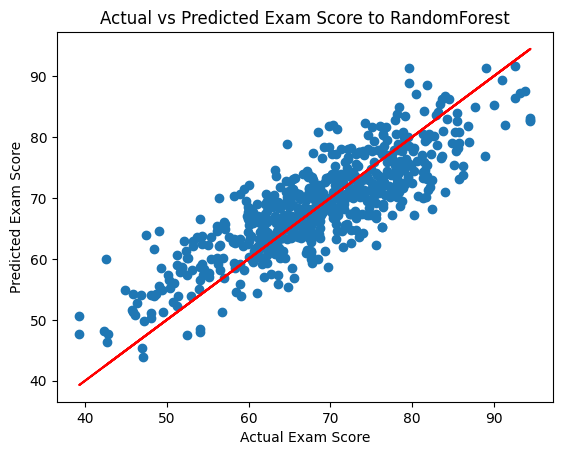

In [440]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring='r2',
    random_state=42
)

random_search.fit(X_train, y_train)
print("Rondom Forist")
print("Best Parameters:", random_search.best_params_)
print("Best R2 Score:", random_search.best_score_)
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print('MSE:',np.round(mse,2))
print('R2 Score:',np.round(r2,2))
plt.scatter(y_test,y_pred)
plt.plot(y_test,y_test,color='red')
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title(f'Actual vs Predicted Exam Score to RandomForest')
plt.show()

Best Parameters: {'fit_intercept': True}
Best R2 Score: 0.47807357534203304
Linear Regression
MSE: 58.16
R2 Score: 0.41


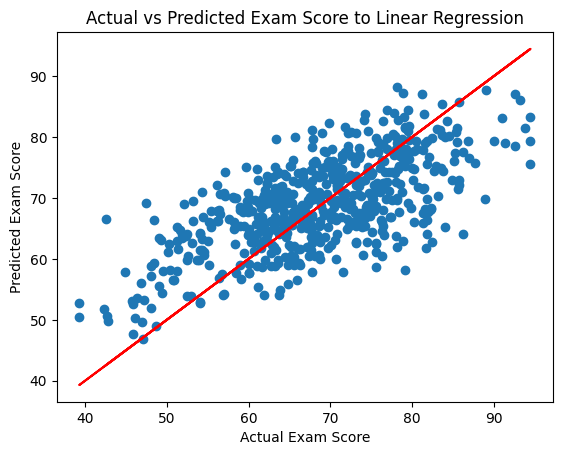

In [418]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LinearRegression

model = LinearRegression()

param_grid = {
    'fit_intercept': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=2,
    cv=5,
    scoring='r2',
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best R2 Score:", random_search.best_score_)

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("Linear Regression")
print('MSE:',np.round(mse,2))
print('R2 Score:',np.round(r2,2))
plt.scatter(y_test,y_pred)
plt.plot(y_test,y_test,color='red')
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title(f'Actual vs Predicted Exam Score to Linear Regression')
plt.show()

Best Parameters: {'min_samples_split': 2, 'min_samples_leaf': 8, 'max_depth': 15, 'criterion': 'squared_error'}
Best R2 Score: 0.6326765866185718
Rondom Forist
MSE: 37.42
R2 Score: 0.62


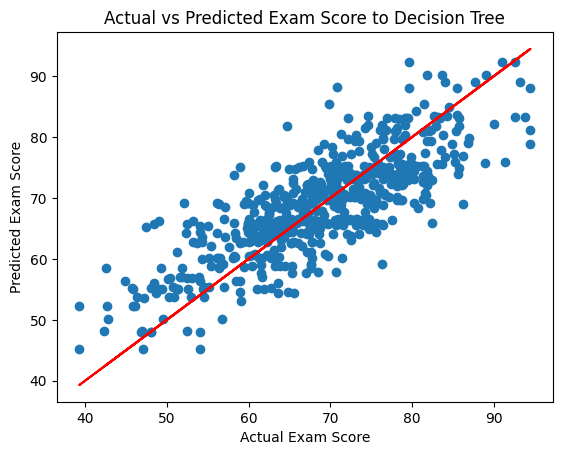

In [419]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(random_state=42)

param_grid = {
    'max_depth': [None, 3, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'criterion': ['squared_error', 'absolute_error']
}

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring='r2',
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best R2 Score:", random_search.best_score_)

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("Rondom Forist")
print('MSE:',np.round(mse,2))
print('R2 Score:',np.round(r2,2))
plt.scatter(y_test,y_pred)
plt.plot(y_test,y_test,color='red')
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title(f'Actual vs Predicted Exam Score to Decision Tree')
plt.show()

In [441]:
import joblib
from google.colab import files

joblib.dump(best_model, 'best_random_forest_model.joblib')

joblib.dump(MMS, 'min_max_scaler.joblib')

encoders = {}
for c_col in X.select_dtypes(include='object').columns:
    from sklearn.preprocessing import LabelEncoder
    le_full = LabelEncoder()
    le_full.fit(X[c_col])
    encoders[c_col] = le_full

joblib.dump(encoders, 'label_encoders.joblib')

print("تم حفظ جميع الملفات بنجاح بصيغة joblib!")

files.download('best_random_forest_model.joblib')
files.download('min_max_scaler.joblib')
files.download('label_encoders.joblib')

تم حفظ جميع الملفات بنجاح بصيغة joblib!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Student Academic Performance Prediction Project Report

This report provides a detailed breakdown of all the steps performed in this notebook to build an end-to-end machine learning pipeline for predicting students' exam scores (Math, Reading, and Writing).

---

## 1. Exploratory Data Analysis (EDA)
* **Data Loading:** The dataset was loaded from an Excel file, and basic inspections were done to understand the schema, columns, and data types.
* **Missing Values Check:** A significant percentage of missing values was identified in the "Test Preparation Course" column.
* **Duplicates Check:** No duplicate rows were found in the dataset.
* **Visual Analysis:** Visualizations (pie charts and count plots) were generated to explore the distribution of categorical features like Gender, Parental Education Level, and Lunch Type.

---

## 2. Data Preprocessing
* **Handling Missing Values:** Missing entries in "Test Preparation Course" were filled with the default value "Not completed" based on the distribution of existing data.
* **Handling Outliers:** The Interquartile Range (IQR) method was applied to numerical columns (Study Time, Absences, and Scores). Outliers were successfully capped using the clip function to prevent them from negatively impacting model training.
* **Data Splitting:** Features (X) were separated from the three target scores (y). The dataset was split into 80% training and 20% testing sets to ensure proper validation.
* **Feature Scaling:** MinMaxScaler was applied to normalize all numerical features into a [0, 1] range.
* **Categorical Encoding:** LabelEncoder was used to transform categorical text variables into numeric format for compatibility with the regression algorithms.

---

## 3. Baseline Model Training and Evaluation
Three baseline models were trained to solve this Multi-output Regression task simultaneously. The initial results were as follows:

* **Linear Regression:**
  * MSE: 58.16
  * R2 Score: 0.41
* **Decision Tree Regressor:**
  * MSE: 58.01
  * R2 Score: 0.41
* **Random Forest Regressor:**
  * MSE: 32.68
  * R2 Score: 0.67

---

## 4. Why was the Random Forest Regressor Selected?
The Random Forest model was chosen as our final deployment model due to the following reasons:
1. **Superior Prediction Performance:** The baseline Random Forest outperformed both Linear Regression and Decision Tree, raising the R2 score from 0.41 to 0.67 and reducing the Mean Squared Error by approximately 44%.
2. **Handling Non-linear Relationships:** Random Forest excels at capturing complex interactions and non-linear patterns between student demographics, study habits, and final scores without requiring complex mathematical feature engineering.
3. **Overfitting Mitigation:** By aggregating predictions from multiple decision trees, the ensemble model reduces variance and generalizes better to unseen test data.

---

## 5. Hyperparameter Tuning Results
To optimize the selected Random Forest model, RandomizedSearchCV was utilized. Below is a comparative summary of the Random Forest model before and after tuning:

| Model State | Mean Squared Error (MSE) | R2 Score | Hyperparameters |
| :--- | :---: | :---: | :--- |
| Before Tuning (Baseline) | 32.68 | 0.67 | Default scikit-learn parameters |
| After Tuning (Optimized) | 31.07 | 0.68 | n_estimators: 300, min_samples_split: 5, max_depth: 10 |

Hyperparameter tuning successfully reduced the prediction error (MSE) to 31.07 and improved the R2 score to 0.68, making our predictions more precise and stable.

---

## 6. Model Export and Deployment Readiness
In the final stage, all necessary objects trained throughout the pipeline were saved using joblib to ensure reproducible inference on new incoming data:
* The optimized predictor model: `best_random_forest_model.joblib`
* The feature scaling tool: `min_max_scaler.joblib`
* The categorical encoders: `label_encoders.joblib`

These files were automatically downloaded and are ready for integration into any production environment or application.